<a href="https://colab.research.google.com/github/vaishnavireddyparupally/ZIDIO/blob/main/RetailPulse_Google_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RetailPulse – Google Colab Dashboard

Converted from your uploaded `app.py`. This notebook keeps the six dashboard sections, Plotly charts, metrics, tables, country filter and CSV downloads.

**Upload these five prepared CSV files when prompted:**
- `cleaned_retail.csv`
- `customer_segments.csv`
- `customer_churn.csv`
- `sales_forecast.csv`
- `inventory_recommendations.csv`

This conversion preserves your original workflow: the notebook reads prepared segment, churn, forecast and inventory CSV outputs. It does not train new ML models.

In [12]:
# 1. Install libraries
!pip -q install pandas numpy matplotlib seaborn plotly scikit-learn openpyxl

import os, sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from google.colab import files
print("Libraries installed and imported successfully.")

Libraries installed and imported successfully.


In [13]:

import pandas as pd
import numpy as np
from google.colab import files
from io import BytesIO

# Upload dataset
uploaded = files.upload()

if uploaded:
    file_name = next(iter(uploaded))
    file_content = uploaded[file_name]

    print("Uploaded file:", file_name)

    # Read CSV or Excel file automatically
    if file_name.lower().endswith(".csv"):
        try:
            raw_df = pd.read_csv(
                BytesIO(file_content), encoding="utf-8"
            )
        except UnicodeDecodeError:
            raw_df = pd.read_csv(
                BytesIO(file_content), encoding="latin1"
            )

    elif file_name.lower().endswith((".xlsx", ".xls")):
        excel_data = pd.read_excel(
            BytesIO(file_content),
            sheet_name=None,
            engine="openpyxl"
        )

        # Combine all Excel sheets
        raw_df = pd.concat(
            excel_data.values(),
            ignore_index=True
        )

    else:
        raise ValueError(
            "Please upload a CSV or Excel file."
        )

    print("Dataset uploaded successfully!")
    print("Dataset shape:", raw_df.shape)

else:
    print("No file uploaded. Creating synthetic demo data.")

    rng = np.random.default_rng(42)
    n = 1000

    dates = pd.Timestamp("2024-01-01") + pd.to_timedelta(
        rng.integers(0, 730, n), unit="D"
    )

    qty = rng.integers(1, 8, n)
    price = np.round(rng.lognormal(2, 0.75, n), 2)
    disc = rng.choice([0, 0.05, 0.10, 0.15, 0.20], n)

    last_dates = dates - pd.to_timedelta(
        rng.integers(0, 240, n), unit="D"
    )

    recency = (pd.Timestamp("2025-12-31") - last_dates).days
    total_purchases = rng.integers(1, 15, n)

    churn = (
        rng.random(n) <
        np.clip(
            0.12 + recency / 400 - total_purchases / 100,
            0.03, 0.92
        )
    ).astype(int)

    raw_df = pd.DataFrame({
        "transaction_id": [f"T{i:05d}" for i in range(1, n+1)],
        "date": dates,
        "customer_id": [
            f"C{x:04d}" for x in rng.integers(1, 301, n)
        ],
        "product_id": [
            f"P{x:04d}" for x in rng.integers(1, 121, n)
        ],
        "category": rng.choice(
            ["Electronics", "Clothing", "Grocery",
             "Beauty", "Sports", "Home & Kitchen"], n
        ),
        "quantity": qty,
        "unit_price": price,
        "discount": disc,
        "revenue": np.round(qty * price * (1-disc), 2),
        "store_id": [
            f"S{x:02d}" for x in rng.integers(1, 11, n)
        ],
        "region": rng.choice(
            ["Hyderabad", "Warangal", "Secunderabad",
             "Chennai", "Pune", "Bengaluru"], n
        ),
        "inventory_level": rng.integers(10, 500, n),
        "reorder_point": rng.integers(25, 100, n),
        "payment_method": rng.choice(
            ["UPI", "Cash", "Credit Card",
             "Debit Card", "Net Banking"], n
        ),
        "customer_age": rng.integers(18, 70, n),
        "gender": rng.choice(["Female", "Male"], n),
        "last_purchase_date": last_dates,
        "total_purchases": total_purchases,
        "total_spend": np.round(
            rng.lognormal(10, 0.8, n), 2
        ),
        "returns": rng.binomial(1, 0.06, n),
        "churn": churn
    })

# Display dataset
display(raw_df.head())

print("Final dataset shape:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

print("\nDataset information:")
raw_df.info()


Saving online_retail_II.xlsx to online_retail_II (3).xlsx
Uploaded file: online_retail_II (3).xlsx
Dataset uploaded successfully!
Dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Final dataset shape: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [14]:
df = raw_df.copy()
rename = {"Invoice":"transaction_id","InvoiceDate":"date","Customer ID":"customer_id",
          "StockCode":"product_id","Description":"category","Quantity":"quantity",
          "Price":"unit_price","Country":"region"}
df = df.rename(columns={k:v for k,v in rename.items() if k in df.columns})
if "date" not in df.columns:
    raise ValueError("Please include a date or InvoiceDate column.")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col, default in {"quantity":1,"unit_price":0,"discount":0}.items():
    if col not in df: df[col] = default
    df[col] = pd.to_numeric(df[col], errors="coerce")
if "revenue" not in df:
    df["revenue"] = df["quantity"] * df["unit_price"] * (1-df["discount"].fillna(0))
df["revenue"] = pd.to_numeric(df["revenue"], errors="coerce")
defaults = {"transaction_id":"Unknown","customer_id":"Unknown","product_id":"Unknown",
            "category":"Other","region":"Unknown","store_id":"Unknown","inventory_level":100,
            "reorder_point":30,"payment_method":"Unknown","customer_age":35,"gender":"Unknown",
            "last_purchase_date":pd.NaT,"total_purchases":1,"total_spend":0,"returns":0,"churn":np.nan}
for col, val in defaults.items():
    if col not in df: df[col] = val
df["last_purchase_date"] = pd.to_datetime(df["last_purchase_date"], errors="coerce")
df = df.dropna(subset=["date","revenue"])
df = df[(df.quantity>0)&(df.unit_price>=0)&(df.revenue>=0)].drop_duplicates()
for col in ["transaction_id","customer_id","product_id","category","region"]:
    df[col] = df[col].fillna("Unknown").astype(str)
if df["last_purchase_date"].isna().all():
    latest_purchase = df.groupby("customer_id")["date"].max()
    df["last_purchase_date"] = df["customer_id"].map(latest_purchase)
if df["churn"].isna().all():
    reference = df.date.max() + pd.Timedelta(days=1)
    df["churn"] = ((reference-df.last_purchase_date).dt.days > 120).astype(int)
else:
    df["churn"] = pd.to_numeric(df.churn,errors="coerce").fillna(0).astype(int).clip(0,1)
print("Cleaned shape:", df.shape)
print("Missing values (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))
display(df.head())

Cleaned shape: (1010535, 21)
Missing values (top 10):


,missing
transaction_id,0
product_id,0
category,0
quantity,0
date,0
unit_price,0
customer_id,0
region,0
discount,0
revenue,0


,transaction_id,product_id,category,quantity,date,unit_price,customer_id,region,discount,revenue,...,inventory_level,reorder_point,payment_method,customer_age,gender,last_purchase_date,total_purchases,total_spend,returns,churn
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,0,83.4,...,100,30,Unknown,35,Unknown,2011-07-05 12:11:00,1,0,0,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,0,81.0,...,100,30,Unknown,35,Unknown,2011-07-05 12:11:00,1,0,0,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,0,81.0,...,100,30,Unknown,35,Unknown,2011-07-05 12:11:00,1,0,0,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,0,100.8,...,100,30,Unknown,35,Unknown,2011-07-05 12:11:00,1,0,0,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,0,30.0,...,100,30,Unknown,35,Unknown,2011-07-05 12:11:00,1,0,0,1


Total revenue: ₹20,476,634.02
Customers: 5882
Transactions: 41939
Regions: 43


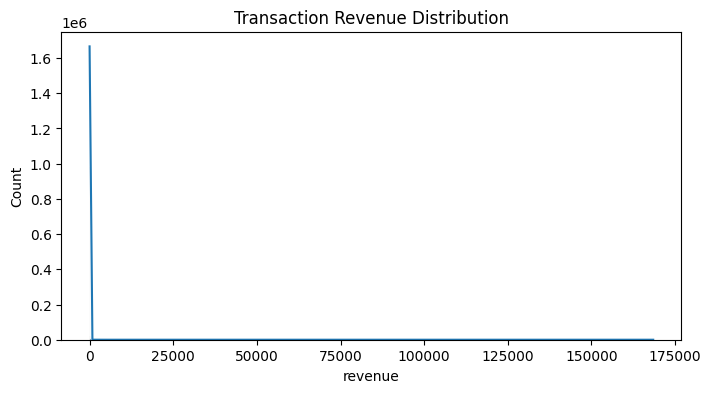

In [15]:
print(f"Total revenue: ₹{df.revenue.sum():,.2f}")
print("Customers:", df.customer_id.nunique())
print("Transactions:", df.transaction_id.nunique())
print("Regions:", df.region.nunique())
monthly = df.set_index("date").resample("MS")["revenue"].sum().reset_index()
fig = px.line(monthly, x="date", y="revenue", markers=True, title="Monthly Revenue Trend")
fig.show()
region_sales = df.groupby("region",as_index=False).revenue.sum().nlargest(10,"revenue")
px.bar(region_sales,x="region",y="revenue",title="Top Regions by Revenue").show()
category_sales = df.groupby("category",as_index=False).revenue.sum().sort_values("revenue",ascending=False)
px.bar(category_sales,x="category",y="revenue",title="Revenue by Category").show()
plt.figure(figsize=(8,4))
sns.histplot(df["revenue"],kde=True)
plt.title("Transaction Revenue Distribution")
plt.show()

In [16]:
reference_date = df.date.max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_id").agg(
    Recency=("date",lambda x:(reference_date-x.max()).days),
    Frequency=("transaction_id","nunique"),
    Monetary=("revenue","sum")
).reset_index()
features = rfm[["Recency","Frequency","Monetary"]].copy()
features["Monetary"] = np.log1p(features["Monetary"].clip(lower=0))
scaled = StandardScaler().fit_transform(features)
k = min(5,max(2,len(rfm)//2))
rfm["Cluster"] = KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(scaled)
rank = rfm.groupby("Cluster").Monetary.mean().sort_values(ascending=False)
segment_names = ["VIP Customers","Loyal Customers","Regular Customers","At-Risk Customers","Lost Customers"]
mapping = {cluster:segment_names[i] for i,cluster in enumerate(rank.index)}
rfm["Segment"] = rfm.Cluster.map(mapping)
display(rfm.head(10))
counts = rfm.Segment.value_counts().reset_index()
counts.columns=["Segment","Customers"]
px.pie(counts,names="Segment",values="Customers",hole=.5,title="Customer Segment Distribution").show()
px.scatter(rfm,x="Frequency",y="Monetary",color="Segment",size="Monetary",title="RFM Customer Behaviour").show()

,customer_id,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,12,77556.46,0,Loyal Customers
1,12347.0,2,8,4921.53,0,Loyal Customers
2,12348.0,75,5,2019.40,0,Loyal Customers
3,12349.0,19,4,4428.69,0,Loyal Customers
4,12350.0,310,1,334.40,1,Regular Customers
5,12351.0,375,1,300.93,1,Regular Customers
6,12352.0,36,10,2849.84,0,Loyal Customers
7,12353.0,204,2,406.76,4,At-Risk Customers
8,12354.0,232,1,1079.40,1,Regular Customers
9,12355.0,214,2,947.61,4,At-Risk Customers


In [17]:
customer = df.groupby("customer_id").agg(
    Recency=("date",lambda x:(reference_date-x.max()).days),
    Frequency=("transaction_id","nunique"),
    Monetary=("revenue","sum"),
    AvgQuantity=("quantity","mean"),
    ReturnRate=("returns","mean"),
    Churn=("churn","max")
).reset_index()
X = customer[["Recency","Frequency","Monetary","AvgQuantity","ReturnRate"]].fillna(0)
y = customer["Churn"].astype(int)
if y.nunique()>1 and len(customer)>=10:
    X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
    churn_model = RandomForestClassifier(n_estimators=150,max_depth=8,random_state=42,class_weight="balanced")
    churn_model.fit(X_train,y_train)
    pred = churn_model.predict(X_test)
    proba_test = churn_model.predict_proba(X_test)[:,1]
    metrics = {"Accuracy":accuracy_score(y_test,pred),"Precision":precision_score(y_test,pred,zero_division=0),
               "Recall":recall_score(y_test,pred,zero_division=0),"F1":f1_score(y_test,pred,zero_division=0)}
    if y_test.nunique()>1: metrics["ROC-AUC"] = roc_auc_score(y_test,proba_test)
    customer["Churn_Probability"] = churn_model.predict_proba(X)[:,1]
    print("Hold-out model metrics:")
    display(pd.DataFrame([metrics]).round(3))
else:
    customer["Churn_Probability"] = y.astype(float)
    print("Not enough class variation to train a classifier; showing target-based risk only.")
customer["Risk_Tier"] = pd.cut(customer.Churn_Probability,[-.001,.5,.8,1.001],labels=["Low Risk","Medium Risk","High Risk"])
display(customer.sort_values("Churn_Probability",ascending=False).head(10))
px.histogram(customer,x="Churn_Probability",color="Risk_Tier",title="Customer Churn Risk Distribution").show()

Hold-out model metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC
0,1.0,1.0,1.0,1.0,1.0


,customer_id,Recency,Frequency,Monetary,AvgQuantity,ReturnRate,Churn,Churn_Probability,Risk_Tier
1915,14280.0,197,1,134.04,6.500000,0.0,1,1.0,High Risk
4719,17112.0,503,1,197.57,2.765957,0.0,1,1.0,High Risk
4715,17108.0,664,1,174.95,3.444444,0.0,1,1.0,High Risk
4713,17106.0,389,1,481.58,3.000000,0.0,1,1.0,High Risk
4709,17102.0,262,1,25.50,2.000000,0.0,1,1.0,High Risk
4681,17074.0,563,1,203.05,4.750000,0.0,1,1.0,High Risk
4840,17234.0,183,1,149.89,3.928571,0.0,1,1.0,High Risk
521,12869.0,682,1,337.67,3.891892,0.0,1,1.0,High Risk
1916,14281.0,408,1,245.15,6.428571,0.0,1,1.0,High Risk
4816,17210.0,393,1,251.72,4.566038,0.0,1,1.0,High Risk


In [18]:
daily = df.groupby("date").quantity.sum().asfreq("D",fill_value=0).rename("units").reset_index()
daily["date"] = pd.to_datetime(daily.date)
if len(daily)>=35:
    work = pd.DataFrame({"y":daily.units.astype(float)})
    for lag in [1,7,14,28]: work[f"lag_{lag}"] = work.y.shift(lag)
    work["dow"] = daily.date.dt.dayofweek.values
    work["month"] = daily.date.dt.month.values
    work = work.dropna()
    feature_cols = ["lag_1","lag_7","lag_14","lag_28","dow","month"]
    demand_model = RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=42)
    demand_model.fit(work[feature_cols],work.y)
    history = list(daily.units.astype(float))
    future_dates = pd.date_range(daily.date.max()+pd.Timedelta(days=1),periods=30,freq="D")
    predictions=[]
    for dt in future_dates:
        row = pd.DataFrame([{"lag_1":history[-1],"lag_7":history[-7],"lag_14":history[-14],
                             "lag_28":history[-28],"dow":dt.dayofweek,"month":dt.month}])
        value = max(0,float(demand_model.predict(row[feature_cols])[0]))
        predictions.append(value); history.append(value)
else:
    future_dates = pd.date_range(daily.date.max()+pd.Timedelta(days=1),periods=30,freq="D")
    predictions = [float(daily.units.mean())]*30
forecast = pd.DataFrame({"ds":future_dates,"yhat":predictions})
print("Forecast next 30 days:",round(forecast.yhat.sum()),"units")
print("Average daily forecast:",round(forecast.yhat.mean()),"units")
history_plot = daily.rename(columns={"date":"ds","units":"units"})
fig = px.line(history_plot,x="ds",y="units",title="Historical Daily Demand")
fig.add_scatter(x=forecast.ds,y=forecast.yhat,mode="lines",name="30-day forecast")
fig.show()
display(forecast.head())

Forecast next 30 days: 0 units
Average daily forecast: 0 units


,ds,yhat
0,2011-12-10 07:45:00,0
1,2011-12-11 07:45:00,0
2,2011-12-12 07:45:00,0
3,2011-12-13 07:45:00,0
4,2011-12-14 07:45:00,0


In [19]:
inventory = df.groupby(["product_id","category"],as_index=False).agg(
    UnitsSold=("quantity","sum"),CurrentStock=("inventory_level","mean"),
    ReorderPoint=("reorder_point","mean"),Revenue=("revenue","sum"))
days = max(1,(df.date.max()-df.date.min()).days+1)
inventory["AvgDailyDemand"] = inventory.UnitsSold/days
inventory["SafetyStock"] = np.ceil(inventory.AvgDailyDemand*7)
demand_based_order = np.ceil(inventory.AvgDailyDemand*30 + inventory.SafetyStock - inventory.CurrentStock)
reorder_point_order = np.ceil(inventory.ReorderPoint - inventory.CurrentStock)
inventory["ReorderQuantity"] = np.maximum(0,np.maximum(demand_based_order,reorder_point_order))
inventory = inventory.sort_values("ReorderQuantity",ascending=False)
print("Total suggested replenishment:",int(inventory.ReorderQuantity.sum()),"units")
display(inventory.head(15))
px.bar(inventory.head(30),x="product_id",y="ReorderQuantity",color="ReorderQuantity",
       title="Top 30 Products for Replenishment").show()

Total suggested replenishment: 336399 units


,product_id,category,UnitsSold,CurrentStock,ReorderPoint,Revenue,AvgDailyDemand,SafetyStock,ReorderQuantity
5077,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106250,100.0,30.0,24445.61,143.775372,1007.0,5221.0
6146,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94147,100.0,30.0,257546.20,127.397835,892.0,4614.0
3978,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,100.0,30.0,168469.60,109.600812,768.0,3957.0
5686,84879,ASSORTED COLOUR BIRD ORNAMENT,80090,100.0,30.0,129324.49,108.376184,759.0,3911.0
3408,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,100.0,30.0,81700.92,105.592693,740.0,3808.0
6106,85099B,JUMBO BAG RED RETROSPOT,77286,100.0,30.0,145961.83,104.581867,733.0,3771.0
161,17003,BROCADE RING PURSE,70379,100.0,30.0,14766.42,95.235453,667.0,3425.0
1764,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,100.0,30.0,28081.73,75.860622,532.0,2708.0
5892,84991,60 TEATIME FAIRY CAKE CASES,54028,100.0,30.0,27041.21,73.109608,512.0,2606.0
2041,22197,SMALL POPCORN HOLDER,48597,100.0,30.0,42699.89,65.760487,461.0,2334.0


In [20]:
from pathlib import Path
out = Path("retailpulse_outputs")
out.mkdir(exist_ok=True)
df.to_csv(out/"cleaned_retail.csv",index=False)
rfm.to_csv(out/"customer_segments.csv",index=False)
customer.to_csv(out/"customer_churn.csv",index=False)
forecast.to_csv(out/"sales_forecast.csv",index=False)
inventory.to_csv(out/"inventory_recommendations.csv",index=False)
print("Created files:")
for p in sorted(out.glob("*.csv")): print("-",p, "|",p.stat().st_size,"bytes")
# Download individual output files if needed:
# files.download("retailpulse_outputs/cleaned_retail.csv")


Created files:
- retailpulse_outputs/cleaned_retail.csv | 163473064 bytes
- retailpulse_outputs/customer_churn.csv | 424345 bytes
- retailpulse_outputs/customer_segments.csv | 241174 bytes
- retailpulse_outputs/inventory_recommendations.csv | 569940 bytes
- retailpulse_outputs/sales_forecast.csv | 668 bytes
